<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## SETTINGS
<div>


In [2]:
# 0. SETTINGS
import os, glob, re, json, shutil, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import probeinterface as pi
from IPython.display import display

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
RAW    = os.path.join(DATA_ROOT, "0_raw")
PROC   = os.path.join(DATA_ROOT, "2_processed")
TABLES = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main\tables"
pilot  = "20260522_r0000136_wt_1750"     # old pilot, only an example session in step 1, step 2c and the sync cell

os.makedirs(TABLES, exist_ok=True)
for name, p in (("DATA_ROOT", DATA_ROOT), ("RAW", RAW), ("PROC", PROC), ("TABLES", TABLES)):
    assert os.path.isdir(p), f"{name} not found: {p}"
print("items in RAW:", len(os.listdir(RAW)), "| items in PROC:", len(os.listdir(PROC)))

items in RAW: 148 | items in PROC: 153


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## Data inventory
Only the two things every analysis uses (read-only):
1. `2_processed\<session>\amir_data\down_sampled\1000_Hz` — the neural data (1000 Hz, no reference).
2. `2_processed\<session>\share` — the behaviour (`trials.csv`) and the sync information (`session_info.json`).
The cell shows both for one example session, then counts how many sessions have them.

<div>

In [3]:
# %%
# ── STEP 1: data inventory — the two things every analysis uses (read-only) ──
import spikeinterface as si
from IPython.display import display
load = getattr(si, "load", None) or si.load_extractor        # si.load (0.105) / si.load_extractor (older)

example = "20260529_r0000136_wt_1318"                          # any session; here the main pilot
HZ1000  = os.path.join(PROC, example, "amir_data", "down_sampled", "1000_Hz")
SHARE   = os.path.join(PROC, example, "share")

def list_folder(folder):
    """Files of a folder with their size in MB, as a table."""
    return pd.DataFrame([{"file": f, "MB": round(os.path.getsize(os.path.join(folder, f)) / 1e6, 2)}
                         for f in sorted(os.listdir(folder))])

# 1. the 1000 Hz recording (neural data)
print(f"1000 Hz folder of {example}:"); display(list_folder(HZ1000))
rec = load(HZ1000)                                             # reads only the metadata, not the traces
dur = rec.get_total_duration()
print(f"\nrecording: {rec.get_sampling_frequency():.0f} Hz | {rec.get_num_channels()} channels "
      f"({384 - rec.get_num_channels()} of 384 removed) | {dur/60:.1f} min")

# 2. the share folder (behaviour + sync)
print(f"\nshare folder of {example}:"); display(list_folder(SHARE))
beh = pd.read_csv(os.path.join(SHARE, "trials.csv"))
print(f"\ntrials.csv: {len(beh)} trials, {beh.shape[1]} columns")
display(beh[["press_np_s", "press_ttl_np_s", "release_np_s", "trial_end_np_s"]].agg(["min", "max"]).round(1))
print(f"recording length: {dur:.1f} s")

# 3. how many sessions have these two things?
sess = [s for s in sorted(os.listdir(PROC)) if os.path.isdir(os.path.join(PROC, s))]
d1000 = lambda s: os.path.join(PROC, s, "amir_data", "down_sampled", "1000_Hz")
has_folder = [s for s in sess if os.path.isdir(d1000(s))]
has_done   = [s for s in sess if os.path.exists(os.path.join(d1000(s), "DONE.txt"))]
has_trials = [s for s in sess if os.path.exists(os.path.join(PROC, s, "share", "trials.csv"))]
counts = pd.DataFrame({"sessions": [len(sess), len(has_folder), len(has_done), len(has_trials)]},
                      index=["folders in 2_processed", "with a 1000_Hz folder", "with DONE.txt", "with share/trials.csv"])
print()
display(counts)
print("1000_Hz folder but no DONE.txt:", sorted(set(has_folder) - set(has_done)))

1000 Hz folder of 20260529_r0000136_wt_1318:


,file,MB
0,DONE.txt,0.00
1,annotations.json,0.00
2,binary.json,0.04
3,probegroup.json,0.25
4,properties,0.00
5,provenance.json,3.56
6,si_folder.json,0.05
7,traces_cached_seg0.raw,2955.08



recording: 1000 Hz | 383 channels (1 of 384 removed) | 32.1 min

share folder of 20260529_r0000136_wt_1318:


,file,MB
0,channel_locations.xlsx,0.01
1,channel_regions.csv,0.03
2,session_info.json,0.00
3,sync_pulses.csv,0.01
4,trials.csv,0.06



trials.csv: 164 trials, 42 columns


,press_np_s,press_ttl_np_s,release_np_s,trial_end_np_s
min,10.1,10.1,11.5,11.5
max,1818.0,1827.5,1821.9,1819.5


recording length: 1928.9 s



,sessions
folders in 2_processed,153
with a 1000_Hz folder,63
with DONE.txt,62
with share/trials.csv,63


1000_Hz folder but no DONE.txt: ['20260522_r0000136_wt_1750']


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## Session list
Goes through every item in `0_raw` and records what it has: an `ap.bin`, a `share\trials.csv`, a synced `trials.csv` (with the column `press_np_s`) and a finished 1000 Hz recording (`DONE.txt`). Usable = has an `ap.bin` and a synced `trials.csv`. The sync information (`sync_ok`, coverage, waiting times) comes from `session_info.json`. Saves `session_inventory.csv` (all items) and `usable_sessions.csv` (usable sessions).

<div>


In [4]:
#STEP 1c: session list (raw ap.bin + synced trials.csv) + sync info from session_info.json ──
rows = []
for s in sorted(os.listdir(RAW)):
    ap = glob.glob(os.path.join(RAW, s, "**", "*.ap.bin"), recursive=True)
    sh = os.path.join(PROC, s, "share", "trials.csv")
    has_trials = os.path.exists(sh)
    ok_sync = has_trials and "press_np_s" in pd.read_csv(sh, nrows=0).columns
    rat = re.search(r"r0+(\d+)", s)
    imro = ""
    meta = glob.glob(os.path.join(RAW, s, "**", "*.ap.meta"), recursive=True)
    if meta:
        with open(meta[0]) as fh:
            m = dict(l.strip().split("=", 1) for l in fh if "=" in l)
        imro = m.get("~imroTbl", "")
    row = {"session": s, "rat": rat.group(1) if rat else None, "n_ap_bin": len(ap),
           "ap_GB": round(sum(os.path.getsize(a) for a in ap) / 1e9, 1),
           "has_trials_csv": has_trials, "synced_trials_csv": bool(ok_sync),
           "has_1000_done": os.path.exists(os.path.join(PROC, s, "amir_data", "down_sampled", "1000_Hz", "DONE.txt")),
           "imro": imro}
    info_file = os.path.join(PROC, s, "share", "session_info.json")
    if os.path.exists(info_file):
        with open(info_file) as fh:
            info = pd.json_normalize(json.load(fh), sep=".").iloc[0]
        row["sync_ok"]       = info.get("sync.sync_ok")
        row["sync_coverage"] = info.get("sync.coverage_frac")
        row["waiting_times"] = str(info.get("behaviour.waiting_times_s"))
    rows.append(row)

sessions = pd.DataFrame(rows)
usable = sessions[(sessions["n_ap_bin"] > 0) & sessions["synced_trials_csv"]].copy()
usable["map_id"] = usable["imro"].astype("category").cat.codes
print(f"items in 0_raw: {len(sessions)} | usable sessions: {len(usable)}  (expected 63)")
print(usable.groupby("rat").size().to_string())

# why is an item not usable?
sessions["reason"] = np.where(sessions["n_ap_bin"] == 0, "no ap.bin",
                     np.where(~sessions["has_trials_csv"], "no trials.csv",
                     np.where(~sessions["synced_trials_csv"], "trials.csv not synced", "usable")))
print("\nall items in 0_raw by reason:"); print(sessions["reason"].value_counts().to_string())

print("\n--- sync check among the usable sessions ---")
print("sync_ok values:", usable["sync_ok"].value_counts(dropna=False).to_dict())
display(usable.loc[usable["sync_ok"] != True, ["session", "rat", "sync_ok", "sync_coverage"]])
print("\n--- foreperiod design among the usable sessions ---")
print(usable.groupby(["rat", "waiting_times"]).size().to_string())

sessions.drop(columns=["imro"]).to_csv(os.path.join(TABLES, "session_inventory.csv"), index=False)
usable.drop(columns=["imro", "has_trials_csv", "has_1000_done"]).to_csv(os.path.join(TABLES, "usable_sessions.csv"), index=False)

items in 0_raw: 148 | usable sessions: 63  (expected 63)
rat
134    14
135    29
136    20

all items in 0_raw by reason:
reason
no ap.bin        71
usable           63
no trials.csv    14

--- sync check among the usable sessions ---
sync_ok values: {np.True_: 54, np.False_: 9}


,session,rat,sync_ok,sync_coverage
58,20260510_r0000135_wt_1625,135,False,0.8741
65,20260511_r0000136_wt_0909,136,False,0.8095
67,20260511_r0000136_wt_1832,136,False,0.7934
77,20260513_r0000136_wt_1729,136,False,0.9487
81,20260514_r0000136_wt_1317,136,False,0.3300
89,20260517_r0000135_wt_1846,135,False,0.1484
93,20260519_r0000136_wt_2031,136,False,0.9419
123,20260611_r0000134_wt_1309,134,False,0.7943
133,20260620_r0000134_wt_1512,134,False,0.9333



--- foreperiod design among the usable sessions ---
rat  waiting_times       
134  [0.3, 0.5, 1.0, 1.3]     2
     [0.3, 0.5, 1.0]          1
     [0.3, 1.0]              10
     [1.0]                    1
135  [0.3, 1.0]              23
     [1.0]                    6
136  [0.3, 1.0]              20


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## Check: is every 1000 Hz recording complete?
For each of the 63 sessions: 
(1) the data file has the size the metadata says (channels × samples × bytes per sample)
(2) the last 5 seconds are not zero in any channel. `DONE.txt` says the save finished, but only (1) and (2) look at the data. The old pilot has no `DONE.txt`, so its answer is the one that matters.
<div>


In [5]:
# CHECK: is every 1000 Hz recording complete? (size + the last 5 s are not zero) ──
import spikeinterface as si
load = getattr(si, "load", None) or si.load_extractor

sessions = pd.read_csv(os.path.join(TABLES, "usable_sessions.csv"), dtype={"rat": str})
rows = []
for _, u in sessions.iterrows():
    s = u["session"]
    f1000 = os.path.join(PROC, s, "amir_data", "down_sampled", "1000_Hz")
    row = {"session": s, "rat": u["rat"], "has_done": os.path.exists(os.path.join(f1000, "DONE.txt"))}
    try:
        rec = load(f1000)                                         # reads only the metadata
        n_samp = (getattr(rec, "get_num_samples", None) or rec.get_num_frames)()
        n_ch = rec.get_num_channels()
        expected = n_ch * n_samp * np.dtype(rec.get_dtype()).itemsize
        actual = os.path.getsize(os.path.join(f1000, "traces_cached_seg0.raw"))
        tail = rec.get_traces(start_frame=n_samp - 5000, end_frame=n_samp)          # last 5 s at 1000 Hz
        row.update({"n_channels": n_ch, "minutes": round(n_samp / rec.get_sampling_frequency() / 60, 1),
                    "expected_GB": round(expected / 1e9, 3), "actual_GB": round(actual / 1e9, 3),
                    "size_ok": expected == actual, "tail_ok": bool((tail.std(axis=0) > 0).all())})
    except Exception as e:
        row.update({"size_ok": False, "tail_ok": False, "error": repr(e)[:120]})
    rows.append(row)
size_chk = pd.DataFrame(rows)
size_chk["complete"] = size_chk["size_ok"] & size_chk["tail_ok"]

bad  = size_chk[~size_chk["complete"]]
no_done = size_chk[~size_chk["has_done"]]
print(f"complete (size and last 5 s): {int(size_chk['complete'].sum())} of {len(size_chk)}")
print(f"not complete: {len(bad)}")
if len(bad):
    display(bad)
print(f"sessions without full downsampled data (no DONE.txt, the save did not finish or an error happened): {len(no_done)}")
if len(no_done):
    display(no_done)

complete (size and last 5 s): 63 of 63
not complete: 0
sessions without full downsampled data (no DONE.txt, the save did not finish or an error happened): 1


,session,rat,has_done,n_channels,minutes,expected_GB,actual_GB,size_ok,tail_ok,complete
19,20260522_r0000136_wt_1750,136,False,383,49.8,4.579,4.579,True,True,True


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## Session flags from the task settings
For every usable session: which `wt` values (waiting time of the trial, s) does it contain?
- `two_wt_session`: has both 0.3 (short) and 1.0 (long).
- `single_wt_session`: has only 1.0. The rat always waits 1.0 s, so there is nothing to compare between short and long.
- `wt_manip_session`: has any other `wt` value (WT-manipulation days). These sessions are excluded from every analysis.

Two columns say which sessions are used for what:
- `include`: all sessions except the WT-manipulation sessions.
- `short_vs_long`: only sessions with both short and long trials. Used for every comparison of short with long.

The short / long / other_wt type of a trial comes from its `wt`, not from the `long` column. The table is saved as `tables\session_flags.csv`.
<div>


In [6]:
# %%
# ── SESSION FLAGS from the task settings: which wt values does each session contain? ──
usable = pd.read_csv(os.path.join(TABLES, "usable_sessions.csv"), dtype={"rat": str})
SHORT_WT, LONG_WT = 0.3, 1.0              # wt of short / long trials (s); every other value = other_wt

rows = []
for _, u in usable.iterrows():
    s = u["session"]
    w = np.round(pd.read_csv(os.path.join(PROC, s, "share", "trials.csv"), usecols=["wt"])["wt"].astype(float), 2)
    typ = pd.Series(np.where(w == SHORT_WT, "short", np.where(w == LONG_WT, "long", np.where(w.isna(), "missing", "other_wt"))))
    n = typ.value_counts()
    rows.append({"session": s, "rat": u["rat"], "wt_values": sorted(w.dropna().unique()), "n_trials": len(w),
                 "n_short": int(n.get("short", 0)), "n_long": int(n.get("long", 0)),
                 "n_other_wt": int(n.get("other_wt", 0)), "n_wt_missing": int(n.get("missing", 0)),
                 "sync_ok": u["sync_ok"], "sync_coverage": u["sync_coverage"]})
flags = pd.DataFrame(rows)
flags["two_wt_session"]    = flags["wt_values"].apply(lambda v: SHORT_WT in v and LONG_WT in v)
flags["single_wt_session"] = flags["wt_values"].apply(lambda v: LONG_WT in v and SHORT_WT not in v)
flags["wt_manip_session"]  = flags["wt_values"].apply(lambda v: any(x not in (SHORT_WT, LONG_WT) for x in v))
flags["wt_values"] = flags["wt_values"].apply(lambda v: " ".join(map(str, v)))

# which sessions are used for what
flags["include"]        = ~flags["wt_manip_session"]                    # all analyses
flags["short_vs_long"]  = flags["include"] & flags["two_wt_session"]    # only analyses that compare short with long
flags["exclude_reason"] = np.where(flags["wt_manip_session"], "WT manipulation", "")

print("design (wt values) per rat:"); print(flags.groupby(["rat", "wt_values"]).size().to_string())
print("\nflags per rat:")
print(flags.groupby("rat")[["two_wt_session", "single_wt_session", "wt_manip_session", "include", "short_vs_long"]].sum().to_string())
print("\ntotal:", int(flags["include"].sum()), "sessions included |", int(flags["short_vs_long"].sum()), "for short vs long")
print("wt_manip sessions:", flags.loc[flags["wt_manip_session"], "session"].tolist())
print("single-wt (only 1.0) sessions:", flags.loc[flags["single_wt_session"], "session"].tolist())
print("sessions with missing wt:", flags.loc[flags["n_wt_missing"] > 0, "session"].tolist())
flags.to_csv(os.path.join(TABLES, "session_flags.csv"), index=False)

design (wt values) per rat:
rat  wt_values      
134  0.3 0.5 1.0         1
     0.3 0.5 1.0 1.3     2
     0.3 1.0            10
     1.0                 1
135  0.3 1.0            23
     1.0                 6
136  0.3 1.0            20

flags per rat:
     two_wt_session  single_wt_session  wt_manip_session  include  short_vs_long
rat                                                                             
134              13                  1                 3       11             10
135              23                  6                 0       29             23
136              20                  0                 0       20             20

total: 60 sessions included | 53 for short vs long
wt_manip sessions: ['20260623_r0000134_wt_1232', '20260624_r0000134_wt_1323', '20260625_r0000134_wt_1820']
single-wt (only 1.0) sessions: ['20260602_r0000135_wt_1715', '20260603_r0000135_wt_1641', '20260609_r0000135_wt_1644', '20260610_r0000135_wt_2313', '20260611_r0000135_wt_1415', '2026

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## Sync details
The `sync` part of every session's `session_info.json`: how well the behaviour clock was matched to the neural clock. The table lists the sessions with `sync_ok` False, lowest coverage first, then compares the two groups. Saved as `tables\sync_summary.csv`.

<div>


In [7]:
# %%
# ── SYNC DETAILS: the sync section of session_info.json for every usable session ──
usable = pd.read_csv(os.path.join(TABLES, "usable_sessions.csv"), dtype={"rat": str})
rows = []
for s in usable["session"]:
    with open(os.path.join(PROC, s, "share", "session_info.json")) as fh:
        sync = json.load(fh).get("sync", {})
    rows.append({"session": s, **{k: (v if np.isscalar(v) else str(v)) for k, v in sync.items()}})
sync_tab = pd.DataFrame(rows).merge(usable[["session", "rat"]], on="session")
print("columns in the sync section:", [c for c in sync_tab.columns if c not in ("session", "rat")])

SHOW = [c for c in ["session", "rat", "sync_ok", "coverage_frac", "n_matched_pulses", "lag_median_s",
                    "lag_std_s", "n_trials_outside_span"] if c in sync_tab.columns]
print("\nsessions with sync_ok False (lowest coverage first):")
display(sync_tab.loc[sync_tab["sync_ok"] != True, SHOW].sort_values("coverage_frac"))

NUM = [c for c in ["coverage_frac", "lag_std_s", "n_trials_outside_span"] if c in sync_tab.columns]
print("\nsync_ok True vs False (min / median / max):")
display(sync_tab.groupby("sync_ok")[NUM].agg(["min", "median", "max"]).round(4))
sync_tab.to_csv(os.path.join(TABLES, "sync_summary.csv"), index=False)

columns in the sync section: ['n_matched_pulses', 'lag_median_s', 'lag_std_s', 'ma_tdt_lag_s', 'pulse_span_behav_s', 'pulse_span_np_s', 'trial_span_behav_s', 'n_trials_outside_span', 'coverage_frac', 'sync_ok']

sessions with sync_ok False (lowest coverage first):


,session,rat,sync_ok,coverage_frac,n_matched_pulses,lag_median_s,lag_std_s,n_trials_outside_span
11,20260517_r0000135_wt_1846,135,False,0.1484,42,7.948329,0.000581,218
7,20260514_r0000136_wt_1317,136,False,0.3300,46,14.449627,0.000368,67
4,20260511_r0000136_wt_1832,136,False,0.7934,115,-383.842925,0.001038,25
40,20260611_r0000134_wt_1309,134,False,0.7943,138,6.972044,0.001181,29
2,20260511_r0000136_wt_0909,136,False,0.8095,47,8.284729,0.000344,8
0,20260510_r0000135_wt_1625,135,False,0.8741,172,-510.467800,0.002353,18
50,20260620_r0000134_wt_1512,134,False,0.9333,40,7.887438,0.000247,2
13,20260519_r0000136_wt_2031,136,False,0.9419,383,-1236.155191,0.002058,10
6,20260513_r0000136_wt_1729,136,False,0.9487,47,6.864702,0.000330,2



sync_ok True vs False (min / median / max):


coverage_frac                 lag_std_s                  \
                  min  median     max       min  median     max   
sync_ok                                                           
False          0.1484  0.8095  0.9487    0.0002  0.0006  0.0024   
True           0.9659  0.9934  1.0000    0.0005  0.0015  0.0059   

        n_trials_outside_span              
                          min median  max  
sync_ok                                    
False                       2   18.0  218  
True                        0    1.0    3

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## Final session list
Usable sessions (63) minus the 3 WT-manipulation sessions = 60 sessions (rat 134: 11, 135: 29, 136: 20).
Kept: single-WT sessions (only 1.0) with short_vs_long = False, so they are left out of short vs long comparisons (53 sessions).
Kept for now: the old pilot (no DONE.txt, but complete) and the 9 sync_ok False sessions (their trials outside the sync span are removed by the trial filter).
Saved to tables/final_sessions.csv. All later cells and notebooks use this file.

<div>

In [10]:
# %%
# ── FINAL SESSION LIST: usable sessions with include == True ──
usable = pd.read_csv(os.path.join(TABLES, "usable_sessions.csv"), dtype={"rat": str})
flags  = pd.read_csv(os.path.join(TABLES, "session_flags.csv"), dtype={"rat": str})
FLAG_COLS = ["session", "two_wt_session", "single_wt_session", "wt_manip_session",
             "include", "short_vs_long", "exclude_reason"]
allf  = usable.merge(flags[FLAG_COLS], on="session", how="left", validate="1:1")
final = allf[allf["include"] == True].reset_index(drop=True)

print(f"usable: {len(allf)} | excluded: {(allf['include'] != True).sum()} | final: {len(final)}  (expected 63 / 3 / 60)")
print("\nexcluded sessions:")
print(allf.loc[allf["include"] != True, ["session", "rat", "exclude_reason"]].to_string(index=False))
summary = pd.DataFrame({"final": final.groupby("rat").size(),
                        "short_vs_long": final.groupby("rat")["short_vs_long"].sum()})
summary.loc["total"] = summary.sum()
print("\nsessions per rat:")
print(summary.to_string())
final.to_csv(os.path.join(TABLES, "final_sessions.csv"), index=False)

usable: 63 | excluded: 3 | final: 60  (expected 63 / 3 / 60)

excluded sessions:
                  session rat  exclude_reason
20260623_r0000134_wt_1232 134 WT manipulation
20260624_r0000134_wt_1323 134 WT manipulation
20260625_r0000134_wt_1820 134 WT manipulation

sessions per rat:
       final  short_vs_long
rat                        
134       11             10
135       29             23
136       20             20
total     60             53


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## Trial filter
Trials from share/trials.csv of the 60 final sessions. Labels: type from wt (0.3 short, 1.0 long); outcome touch > correct > early > late, else other.
Press on the neural clock = press_ttl_np_s, else press_np_s. Tone and release = press + MA interval (same clock).
Rules (a trial is excluded if any applies):
R1 no press time (neither TTL nor press_np_s) | R2 touch | R3 early with hold >= 1.05 s | R4 other |
R5 timing_mismatch = WT <= hold < tone delay, or correct with rt > 0.5 s (excluded since 2026-10-23).
All long_prob blocks kept. Saved: tables/trials_filtered.csv (all trials, flag columns, keep).

<div>


In [34]:
# %%
# ── TRIAL FILTER: trials of the final sessions, rules R1–R5 ──
final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
TONE_DELAY     = {0.3: 0.35, 1.0: 1.05}   # measured tone − press delay (s)
EARLY_MAX_HOLD = 1.05                     # R3 (">=" — confirm vs ">")
RESP_WIN       = 0.5                      # correct = release within 0.5 s after the tone

parts = []
for _, s in final.iterrows():
    t = pd.read_csv(os.path.join(PROC, s["session"], "share", "trials.csv"))
    t.insert(0, "session", s["session"]); t.insert(1, "rat", s["rat"])
    parts.append(t)
T = pd.concat(parts, ignore_index=True)

# labels
wt = T["wt"].round(2)
T["type"]  = np.select([wt == 0.3, wt == 1.0], ["short", "long"], "other_wt")
T["label"] = np.select([T["is_touch"] == 1, T["correct"] == 1, T["early"] == 1, T["late"] == 1],
                       ["touch", "correct", "early", "late"], "other")
T["prev_outcome"] = T.groupby("session")["label"].shift(1)
T["latency_to_press_s"] = T["press"] - T.groupby("session")["trial_end"].shift(1)

# times on the neural clock (press from TTL, else press_np_s; tone/release = press + MA interval)
T["press_from_ttl"]   = T["press_ttl_np_s"].notna()
T["press_neural_s"]   = T["press_ttl_np_s"].fillna(T["press_np_s"])
tone = T["tone"].where(T["tone"] > 0)                       # trials.csv writes 0 when no tone was played
T["tone_neural_s"]    = T["press_neural_s"] + (tone - T["press"])
T["release_neural_s"] = T["press_neural_s"] + (T["release"] - T["press"])
T["rt_s"] = T["release"] - tone
hold = T["hold_duration"]
T["timing_mismatch"] = (((hold >= wt) & (hold < wt.map(TONE_DELAY)))
                        | ((T["label"] == "correct") & (T["rt_s"] > RESP_WIN)))

# rules
T["R1_no_press"]       = T["press_neural_s"].isna()
T["R2_touch"]          = T["label"] == "touch"
T["R3_early_hold"]     = (T["label"] == "early") & (hold > EARLY_MAX_HOLD)
T["R4_other"]          = T["label"] == "other"
T["R5_timing_mismatch"] = T["timing_mismatch"]
RULES = ["R1_no_press", "R2_touch", "R3_early_hold", "R4_other", "R5_timing_mismatch"]
T["keep"] = ~T[RULES].any(axis=1)

# funnel (rules applied one after the other)
left = pd.Series(True, index=T.index)
fun = [{"step": "start", **T.groupby("rat").size().to_dict(), "total": len(T), "sessions": T["session"].nunique()}]
for r in RULES:
    left &= ~T[r]
    k = T[left]
    fun.append({"step": f"− {r}", **k.groupby("rat").size().to_dict(), "total": len(k), "sessions": k["session"].nunique()})
print("trial funnel:"); print(pd.DataFrame(fun).to_string(index=False))
print("\nonly-this-rule counts:", {r: int((T[r] & (T[RULES].sum(axis=1) == 1)).sum()) for r in RULES})

K = T[T["keep"]]
print(f"\nkept: {len(K)} of {len(T)} trials | press from TTL: {K['press_from_ttl'].sum()} | from press_np_s: {(~K['press_from_ttl']).sum()}")
print("final sessions with 0 kept trials:", sorted(set(final["session"]) - set(K["session"])))
print("\nkept trials per rat, type x outcome:")
print(pd.crosstab(K["rat"], [K["type"], K["label"]], margins=True).to_string())
pd.DataFrame(fun).to_csv(os.path.join(TABLES, "trial_funnel.csv"), index=False)
T.to_csv(os.path.join(TABLES, "trials_filtered.csv"), index=False)
print("kept trials with a tone, by label:", K.groupby("label")["tone_neural_s"].apply(lambda v: v.notna().sum()).to_dict())

trial funnel:
                step  134  135  136  total  sessions
               start 1650 5339 2888   9877        60
       − R1_no_press 1619 5101 2780   9500        60
          − R2_touch 1529 4810 2528   8867        60
     − R3_early_hold 1529 4810 2528   8867        60
          − R4_other 1529 4809 2499   8837        60
− R5_timing_mismatch 1504 4659 2452   8615        60

only-this-rule counts: {'R1_no_press': 306, 'R2_touch': 633, 'R3_early_hold': 0, 'R4_other': 30, 'R5_timing_mismatch': 222}

kept: 8615 of 9877 trials | press from TTL: 7851 | from press_np_s: 764
final sessions with 0 kept trials: []

kept trials per rat, type x outcome:
type     long              short               All
label correct early late correct early  late      
rat                                               
134       654   150  164     344    33   159  1504
135      1265  1704  196     892   183   419  4659
136       824   409  130     507   101   481  2452
All      2743  2263  490    1743   

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## electrode maps (final sessions)
Each distinct electrode map (`~imroTbl` in ap.meta) has a `map_id` from step 1c (numbered over the 63 usable sessions).
For each map used by the 60 final sessions: rats, number of sessions, and per shank the number of channels and depth range
(y = distance from the tip, µm; small y = deep). Saved to tables/electrode_maps.csv.#

<div>

In [13]:

# where on the probe does each electrode map record? (final sessions) ──
final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
rows = []
for mid, g in final.groupby("map_id"):
    s = g["session"].iloc[0]                                   # one example session per map
    meta = glob.glob(os.path.join(RAW, s, "**", "*.ap.meta"), recursive=True)[0]
    probe = pi.read_spikeglx(meta)
    pos, shank = probe.contact_positions, probe.shank_ids.astype(int)
    for sh in np.unique(shank):
        y = pos[shank == sh, 1]
        rows.append({"map_id": mid, "rats": " ".join(sorted(g["rat"].unique())), "n_sessions": len(g),
                     "shank": sh, "n_channels": len(y), "y_min_um": int(y.min()), "y_max_um": int(y.max())})
maps = pd.DataFrame(rows)
per_map = maps.groupby("map_id").agg(n_sessions=("n_sessions", "first"), n_channels=("n_channels", "sum"))
print(f"electrode maps in final sessions: {maps['map_id'].nunique()} | sessions: {per_map['n_sessions'].sum()}  (expected 60)")
print("maps not used by final sessions:", sorted(set(range(12)) - set(maps["map_id"])))
print("\n", maps.to_string(index=False))
maps.to_csv(os.path.join(TABLES, "electrode_maps.csv"), index=False)

electrode maps in final sessions: 12 | sessions: 60  (expected 60)
maps not used by final sessions: []

  map_id rats  n_sessions  shank  n_channels  y_min_um  y_max_um
      0  136           8      0          96         0      1425
      0  136           8      1          96         0      1425
      0  136           8      2          96         0      1425
      0  136           8      3          96         0      1425
      1  135           3      0          96         0      1425
      1  135           3      1          96         0      1425
      1  135           3      2          96         0      1425
      1  135           3      3          96         0      1425
      2  134           4      0           1      2400      2400
      2  134           4      1         182       285      2970
      2  134           4      2         147         0      2565
      2  134           4      3          54       615      3150
      3  136          11      0         119      1560      3690

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## depth coverage (final sessions)
For each rat × shank × 100 µm depth bin (y from the tip): number of final sessions whose electrode map records there.
Bins with >= 5 sessions can be tested (statistics rule). Raw electrode maps (before bad-channel removal).
Saved: tables/depth_coverage.csv and depth_coverage.png.

bins recorded and bins with >= 5 sessions, per rat:
     bins_recorded  bins_testable  sessions
rat                                        
134             76             64        11
135            158             93        29
136            130            111        20


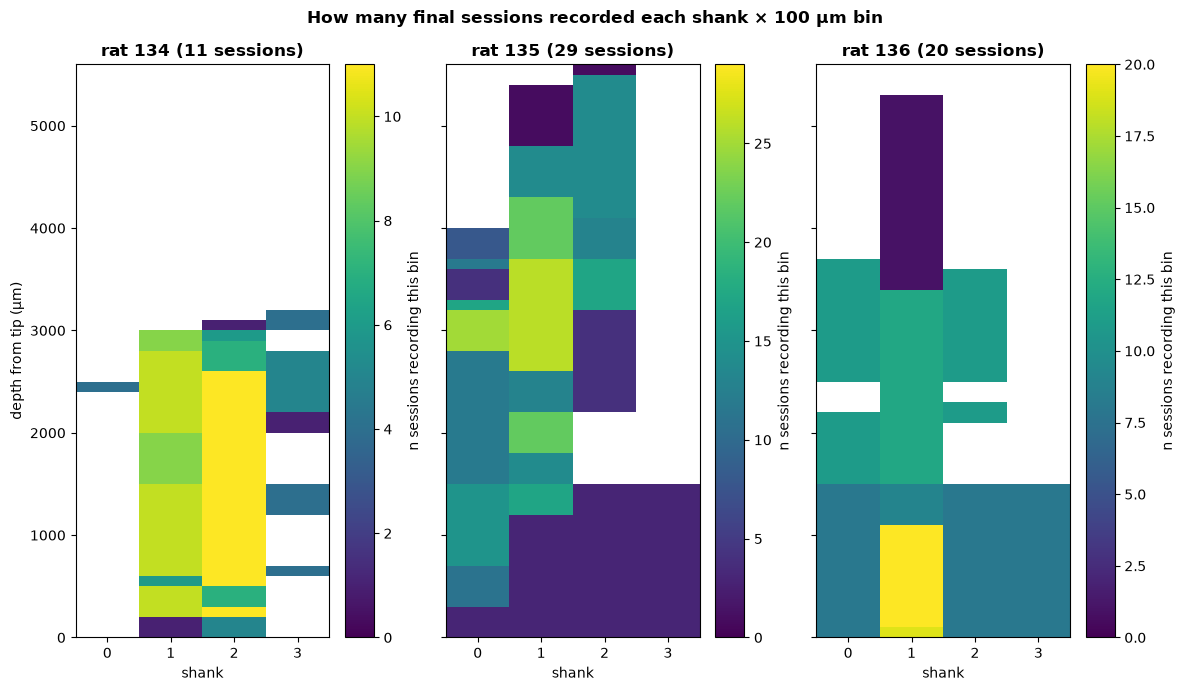

In [14]:
# depth coverage per rat x shank x 100 um bin (final sessions) ──
final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
BIN, MIN_SESS = 100, 5

# electrode positions once per map (all sessions with the same map_id record the same sites)
map_bins = {}
for mid, g in final.groupby("map_id"):
    meta = glob.glob(os.path.join(RAW, g["session"].iloc[0], "**", "*.ap.meta"), recursive=True)[0]
    probe = pi.read_spikeglx(meta)
    map_bins[mid] = pd.DataFrame({"shank": probe.shank_ids.astype(int),
                                  "bin": (probe.contact_positions[:, 1] // BIN).astype(int) * BIN}).drop_duplicates()

cov = pd.concat([map_bins[r["map_id"]].assign(rat=r["rat"], session=r["session"]) for _, r in final.iterrows()])
n_cov = cov.groupby(["rat", "shank", "bin"])["session"].nunique().rename("n_sessions").reset_index()
n_cov.to_csv(os.path.join(TABLES, "depth_coverage.csv"), index=False)

summ = n_cov.assign(ok=n_cov["n_sessions"] >= MIN_SESS).groupby("rat").agg(
    bins_recorded=("bin", "size"), bins_testable=("ok", "sum"))
summ["sessions"] = final.groupby("rat").size()
print(f"bins recorded and bins with >= {MIN_SESS} sessions, per rat:")
print(summ.to_string())

rats = sorted(n_cov["rat"].unique())
full = np.arange(0, n_cov["bin"].max() + BIN, BIN)            # every bin, also empty ones
fig, axes = plt.subplots(1, len(rats), figsize=(4 * len(rats), 7), sharey=True)
for ax, rat in zip(axes, rats):
    piv = (n_cov[n_cov["rat"] == rat].pivot(index="bin", columns="shank", values="n_sessions")
           .reindex(index=full, columns=range(4)))
    n_rat = int(summ.loc[rat, "sessions"])
    im = ax.imshow(piv.values, origin="lower", aspect="auto", cmap="viridis", vmin=0, vmax=n_rat,
                   extent=[-0.5, 3.5, 0, full[-1] + BIN])
    ax.set_xticks(range(4)); ax.set_xlabel("shank")
    ax.set_title(f"rat {rat} ({n_rat} sessions)", fontweight="bold")
    fig.colorbar(im, ax=ax, label="n sessions recording this bin")
axes[0].set_ylabel("depth from tip (µm)")
fig.suptitle("How many final sessions recorded each shank × 100 µm bin", fontweight="bold")
plt.tight_layout(); plt.savefig(os.path.join(TABLES, "depth_coverage.png"), dpi=150); plt.show()

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## Task settings per session
Distinct values of the setting columns in each final session's share\trials.csv, plus licks.npz present and % outcomes (all trials, before the trial filter).
RESULT 2026-10-16 (63 sessions): catch and vibration always 0; long_prob changes within sessions (blocks);
wt 0.3/1.0 (real_wt 0.32/1.02); reward_size varies (unit depends on MA version, don't pool); tone 8 kHz, 0.2 s.
Saved: tables/task_settings_per_session.csv.

<div >


In [17]:
# %%
# ── TASK SETTINGS PER SESSION (final sessions) ──
final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
SETTING_COLS = ["catch", "vibration", "long_prob", "wt", "real_wt", "reward_size",
                "tone_frequency", "tone_amplitude", "tone_duration"]
rows = []
for _, u in final.iterrows():
    s = u["session"]
    beh = pd.read_csv(os.path.join(PROC, s, "share", "trials.csv"))
    row = {"session": s, "rat": u["rat"], "n_trials": len(beh),
           "licks_npz": os.path.exists(os.path.join(PROC, s, "licks.npz")),
           "pct_correct": round(100 * beh["correct"].mean(), 1),
           "pct_early": round(100 * beh["early"].mean(), 1),
           "pct_late": round(100 * beh["late"].mean(), 1),
           "pct_long": round(100 * (beh["wt"].round(2) == 1.0).mean(), 1),     # from wt, not the 'long' column
           "n_touch": int(beh["is_touch"].astype(bool).sum())}
    for c in SETTING_COLS:
        v = np.sort(beh[c].dropna().unique())
        row[c] = (", ".join(map(str, np.round(v.astype(float), 3))) if len(v) <= 4
                  else f"{len(v)} values, {np.min(v):.3g}–{np.max(v):.3g}")
    rows.append(row)
tasks = pd.DataFrame(rows)
tasks.to_csv(os.path.join(TABLES, "task_settings_per_session.csv"), index=False)

print(f"sessions: {len(tasks)}  (expected 60) | missing licks.npz: {(~tasks['licks_npz']).sum()}")
print("\nper rat (median, min, max):")
print(tasks.groupby("rat")[["n_trials", "pct_correct", "pct_early", "pct_late", "pct_long"]]
      .agg(["median", "min", "max"]).round(1))
for c in SETTING_COLS:
    print(f"\n{c}:"); print(tasks.groupby("rat")[c].value_counts().to_string())

sessions: 60  (expected 60) | missing licks.npz: 0

per rat (median, min, max):
    n_trials          pct_correct             pct_early             pct_late  \
      median min  max      median   min   max    median   min   max   median   
rat                                                                            
134    145.0  30  234        62.8  50.0  81.2      15.8   4.1  33.3     16.7   
135    182.0  88  310        45.3   9.8  64.7      41.2  14.8  89.5     10.3   
136    150.5  39  218        50.0  36.7  63.0      27.0  16.5  44.2     18.4   

               pct_long               
     min   max   median   min    max  
rat                                   
134  5.8  38.6     60.4  41.4  100.0  
135  0.0  42.6     59.1  35.5  100.0  
136  5.8  35.8     57.5  45.0   66.7  

catch:
rat  catch
134  0.0      11
135  0.0      29
136  0.0      20

vibration:
rat  vibration
134  0.0          11
135  0.0          29
136  0.0          20

long_prob:
rat  long_prob            
134  0

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## Tone delays and long_prob blocks
Per final session: measured tone − press delays (trials with a tone) and the long_prob block structure.
RESULT 2026-10-16 (63 sessions): delays exactly 0.35 / 1.05 s (not real_wt 0.32 / 1.02); long_prob switches in blocks (median 7 switches).
Saved: tables/tone_delay_longprob_check.csv.

<div>


In [19]:

# TONE DELAYS + LONG_PROB BLOCKS (final sessions) ──
final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
rows = []
for _, u in final.iterrows():
    beh = pd.read_csv(os.path.join(PROC, u["session"], "share", "trials.csv"))
    tone_ok = beh["tone"] > 0
    delay = ((beh["tone"] - beh["press"])[tone_ok]).round(2)
    lp = beh["long_prob"].round(2)
    rows.append({"session": u["session"], "rat": u["rat"],
                 "tone_delays_s": ", ".join(f"{d}({n})" for d, n in delay.value_counts().sort_index().items()),
                 "other_delays": int((~delay.isin([0.35, 1.05])).sum()),
                 "n_lp_switches": int((lp != lp.shift()).sum() - 1),
                 "trials_per_long_prob": ", ".join(f"{v}:{n}" for v, n in lp.value_counts().sort_index().items())})
chk = pd.DataFrame(rows)
chk.to_csv(os.path.join(TABLES, "tone_delay_longprob_check.csv"), index=False)
print(chk.to_string(index=False))
print(f"\nsessions: {len(chk)} | trials with a delay other than 0.35 / 1.05 s: {chk['other_delays'].sum()}")
print("long_prob switches per session, per rat (median, min, max):")
print(chk.groupby("rat")["n_lp_switches"].agg(["median", "min", "max"]))

                  session rat       tone_delays_s  other_delays  n_lp_switches               trials_per_long_prob
20260510_r0000135_wt_1625 135   0.35(12), 1.05(4)             0              1                   0.5:112, 0.75:31
20260510_r0000136_wt_1926 136  0.35(55), 1.05(65)             0              8                    0.5:89, 0.75:81
20260511_r0000136_wt_0909 136  0.35(11), 1.05(21)             0              2                    0.5:27, 0.75:15
20260511_r0000136_wt_0930 136  0.35(27), 1.05(39)             0              4                    0.5:54, 0.75:32
20260511_r0000136_wt_1832 136  0.35(47), 1.05(50)             0              5                    0.5:75, 0.75:46
20260512_r0000136_wt_1054 136  0.35(39), 1.05(56)             0              7                    0.5:61, 0.75:67
20260513_r0000136_wt_1729 136  0.35(13), 1.05(17)             0              1                    0.5:22, 0.75:17
20260514_r0000136_wt_1317 136  0.35(36), 1.05(37)             0              6          

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## Probe location per session (brain region per recorded channel)
Each session has its own share/channel_regions.csv and channel_locations.xlsx (the electrode map changes between sessions).
P1 inventory: files there? xlsx agrees with csv? every recorded channel (1000 Hz recording, after bad-channel removal) matched by POSITION
(file x = probe x + 27 µm, same depth); also checks that the channel NUMBER points to the same depth.
P2 per rat: same electrode position -> same region in every session?   P3 plots per rat.   P4/P4b probe orientation.
Output: tables/channel_regions_all.csv, tables/channel_regions_inventory.csv, figures/probe_location.
RESULT 2026-10-20 (59 sessions): all files present, 100% matched, 0 region conflicts.

<div>


In [20]:
# %%
# ── P1 inventory: files per session + match with the recording's channel positions (final sessions) ──
FIG_LOC = os.path.join(os.path.dirname(TABLES), "figures", "probe_location"); os.makedirs(FIG_LOC, exist_ok=True)
final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
RAT = final.set_index("session")["rat"]
USED = final["session"].tolist()
print(len(USED), "final sessions")

inv, maps = [], []
for s in USED:
    row = {"session": s, "rat": RAT[s]}
    try:
        d = os.path.join(PROC, s)
        csv = glob.glob(os.path.join(d, "**", "*channel_regions*.csv"), recursive=True)
        xls = glob.glob(os.path.join(d, "**", "*channel_locations*.xlsx"), recursive=True)
        row.update(n_csv=len(csv), n_xlsx=len(xls), csv_file=csv[0] if csv else "", xlsx_file=xls[0] if xls else "")
        if len(csv) != 1:
            inv.append(row); print(s, "-> channel_regions.csv found:", len(csv)); continue
        reg = pd.read_csv(csv[0])
        row.update(file_rows=len(reg), file_depth_min=reg["depth_um"].min(), file_depth_max=reg["depth_um"].max(),
                   file_regions="; ".join(f"{k} {v}" for k, v in reg["brain_region"].value_counts().items()))
        if len(xls) == 1:
            lx = pd.read_excel(xls[0]).set_index("channel_id")["location"]
            row["xlsx_agrees_%"] = round(100 * (reg["brain_region"].values == lx.reindex(reg["channel"]).values).mean(), 1)
        rec = load(os.path.join(d, "amir_data", "down_sampled", "1000_Hz"))       # only positions are used
        loc = rec.get_channel_locations()
        row["rec_x"] = str(sorted(np.unique(np.round(loc[:, 0])).astype(int).tolist()))
        row["file_x"] = str(sorted(np.unique(np.round(reg["x_um"])).astype(int).tolist()))
        # exact match: file x = probe x + 27 µm, same depth
        key = {(round(x) - 27, round(y)): i for i, (x, y) in enumerate(zip(reg["x_um"], reg["depth_um"]))}
        row["file_dup_positions"] = len(reg) - len(key)                           # should be 0
        idx = np.array([key.get((round(x), round(y)), -1) for x, y in loc])
        ok_ = idx >= 0
        sub = reg.iloc[np.where(ok_, idx, 0)]
        m = pd.DataFrame({"session": s, "rat": row["rat"], "channel_id": rec.get_channel_ids(),
                          "x": loc[:, 0], "y": loc[:, 1],
                          "region": np.where(ok_, sub["brain_region"].values, "NOT IN FILE"),
                          "ap_mm": np.where(ok_, sub["ap_mm"].values, np.nan),
                          "ml_mm": np.where(ok_, sub["ml_mm"].values, np.nan),
                          "dv_mm": np.where(ok_, sub["dv_mm"].values, np.nan)})
        # extra check: does the channel NUMBER also point to the same depth?
        num = pd.Series(rec.get_channel_ids()).astype(str).str.extract(r"(\d+)$")[0].astype(float)
        fy = reg.set_index("channel")["depth_um"].reindex(num).values
        row["chan_number_same_y_%"] = round(100 * np.mean(np.isclose(fy, loc[:, 1])), 1)
        maps.append(m)
        vc = m["region"].value_counts()
        row.update(rec_channels=len(m), rec_y_min=loc[:, 1].min(), rec_y_max=loc[:, 1].max(),
                   matched_pct=round(100 * (m["region"] != "NOT IN FILE").mean(), 1),
                   n_PL=int(vc.get("Prelimbic area", 0)), n_IL=int(vc.get("Infralimbic area", 0)),
                   n_other=int((~m["region"].isin(["Prelimbic area", "Infralimbic area", "NOT IN FILE"])).sum()),
                   n_not_in_file=int(vc.get("NOT IN FILE", 0)))
    except Exception as e:
        row["error"] = repr(e)
    inv.append(row)
    print(s, {k: row.get(k) for k in ("n_csv", "n_xlsx", "matched_pct", "n_PL", "n_IL", "n_other", "error") if k in row},
          flush=True)

INV = pd.DataFrame(inv)
CH_REG = pd.concat(maps, ignore_index=True) if maps else pd.DataFrame()
INV.to_csv(os.path.join(TABLES, "channel_regions_inventory.csv"), index=False)
CH_REG.to_csv(os.path.join(TABLES, "channel_regions_all.csv"), index=False)
COLS = ["rat", "n_csv", "n_xlsx", "xlsx_agrees_%", "file_depth_min", "file_depth_max",
        "rec_y_min", "rec_y_max", "matched_pct", "n_PL", "n_IL", "n_other",
        "n_not_in_file", "file_regions", "error", "rec_x", "file_x", "file_dup_positions", "chan_number_same_y_%"]
print(INV.set_index("session")[[c for c in COLS if c in INV]].to_string())

print("\nmissing / more than one channel_regions.csv:", INV.loc[INV["n_csv"].fillna(0) != 1, "session"].tolist())
if "matched_pct" in INV:
    print("not 100% matched by position:", INV.loc[INV["matched_pct"].fillna(0) < 100, "session"].tolist())
print("sessions with an error:", INV.loc[INV["error"].notna(), "session"].tolist() if "error" in INV else [])
print("new compared with the 59 earlier sessions: check 20260521_r0000136_wt_1221 ->",
      "in list" if "20260521_r0000136_wt_1221" in USED else "not in list")

60 final sessions
20260510_r0000135_wt_1625 {'n_csv': 1, 'n_xlsx': 1, 'matched_pct': np.float64(100.0), 'n_PL': 0, 'n_IL': 247, 'n_other': 129}
20260510_r0000136_wt_1926 {'n_csv': 1, 'n_xlsx': 1, 'matched_pct': np.float64(100.0), 'n_PL': 140, 'n_IL': 243, 'n_other': 0}
20260511_r0000136_wt_0909 {'n_csv': 1, 'n_xlsx': 1, 'matched_pct': np.float64(100.0), 'n_PL': 140, 'n_IL': 243, 'n_other': 0}
20260511_r0000136_wt_0930 {'n_csv': 1, 'n_xlsx': 1, 'matched_pct': np.float64(100.0), 'n_PL': 140, 'n_IL': 243, 'n_other': 0}
20260511_r0000136_wt_1832 {'n_csv': 1, 'n_xlsx': 1, 'matched_pct': np.float64(100.0), 'n_PL': 140, 'n_IL': 243, 'n_other': 0}
20260512_r0000136_wt_1054 {'n_csv': 1, 'n_xlsx': 1, 'matched_pct': np.float64(100.0), 'n_PL': 140, 'n_IL': 243, 'n_other': 0}
20260513_r0000136_wt_1729 {'n_csv': 1, 'n_xlsx': 1, 'matched_pct': np.float64(100.0), 'n_PL': 140, 'n_IL': 243, 'n_other': 0}
20260514_r0000136_wt_1317 {'n_csv': 1, 'n_xlsx': 1, 'matched_pct': np.float64(100.0), 'n_PL': 140, '

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### P2: region consistency per rat
Same electrode position (x, y) -> same region in every session of a rat? Conflicts listed (should be 0).
Then the y range (µm from the tip) of every region per rat and shank.
RESULT 2026-10-20 (59 sessions): 0 conflicts.

<div>


In [21]:
# %%
# ── P2 consistency per rat: same electrode position -> same region in every session? ──
g = CH_REG[CH_REG["region"] != "NOT IN FILE"].groupby(["rat", "x", "y"])["region"]
cons = g.agg(n_sessions="size", n_regions="nunique",
             regions=lambda r: "; ".join(f"{k} {v}" for k, v in r.value_counts().items())).reset_index()
for rat, c in cons.groupby("rat"):
    bad = c[c["n_regions"] > 1]
    print(f"rat {rat}: {len(c)} electrode positions recorded, {len(bad)} with different regions across sessions")
    if len(bad):
        print(bad.sort_values(["x", "y"]).head(30).to_string(index=False))
CH_REG["shank"] = (CH_REG["x"] // 250).astype(int)
b = CH_REG.groupby(["rat", "shank", "region"])["y"].agg(["min", "max"]).unstack("region")
print("\ny range (µm) per rat, shank and region:\n", b.to_string())

rat 134: 848 electrode positions recorded, 0 with different regions across sessions
rat 135: 1368 electrode positions recorded, 0 with different regions across sessions
rat 136: 1010 electrode positions recorded, 0 with different regions across sessions

y range (µm) per rat, shank and region:
                                           min                                                                                                                 max                                                                                
region    Basal forebrain region, unspecified Cingulate area 1 Infralimbic area Not found Prelimbic area Secondary motor area Basal forebrain region, unspecified Cingulate area 1 Infralimbic area Not found Prelimbic area Secondary motor area
rat shank                                                                                                                                                                                                                   

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### P3: probe plots per rat
Per rat: one panel per final session (4 shanks, recorded channels coloured by region; title = date, PL and IL channel counts),
last panel = all sessions together. Saved: figures/probe_location/probe_regions_rat_<rat>.png.

<div>


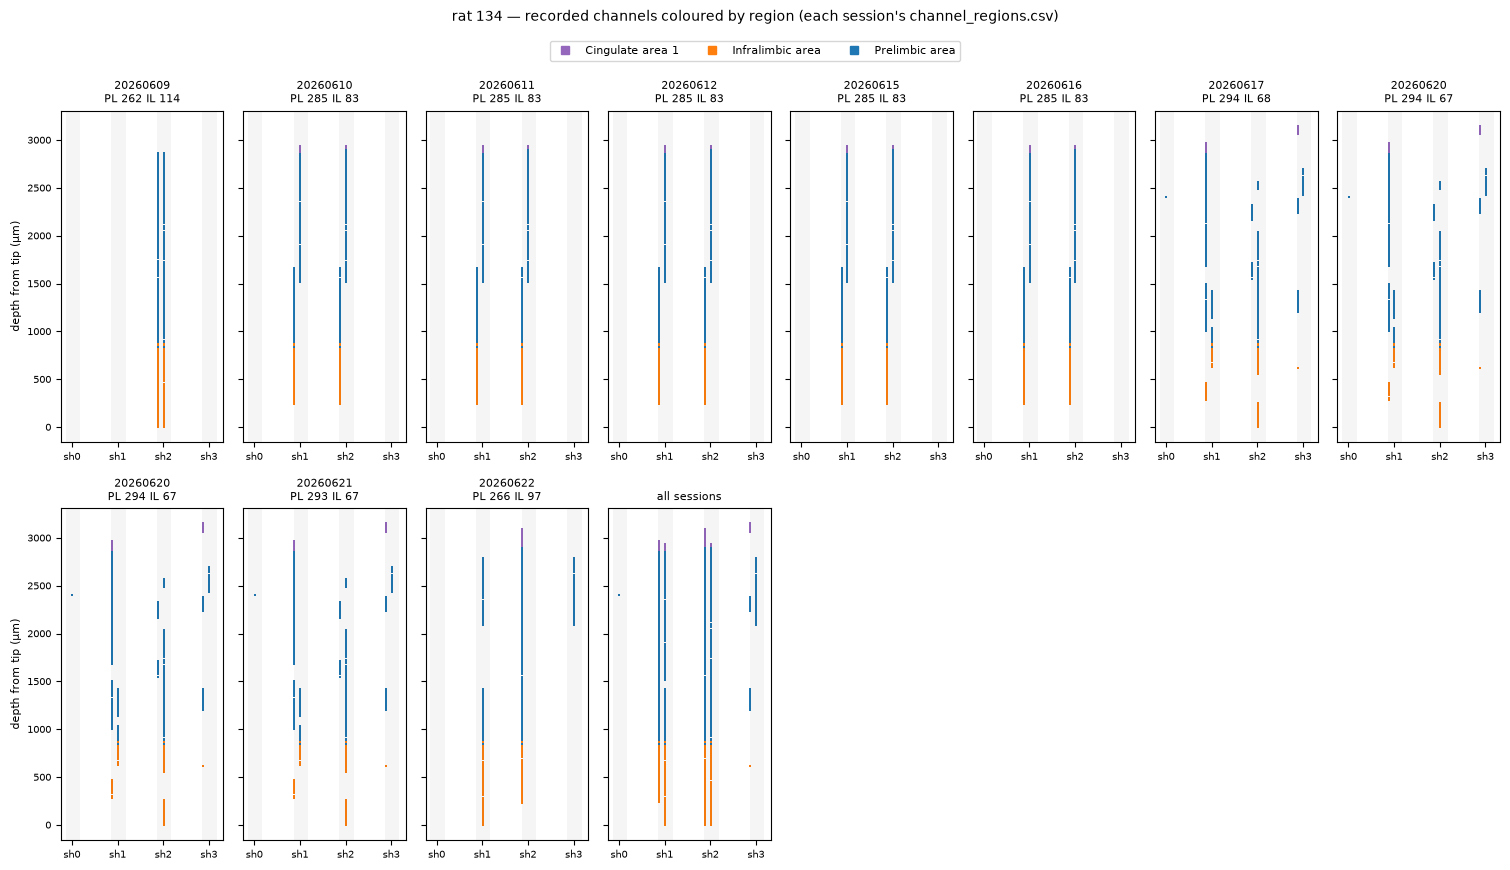

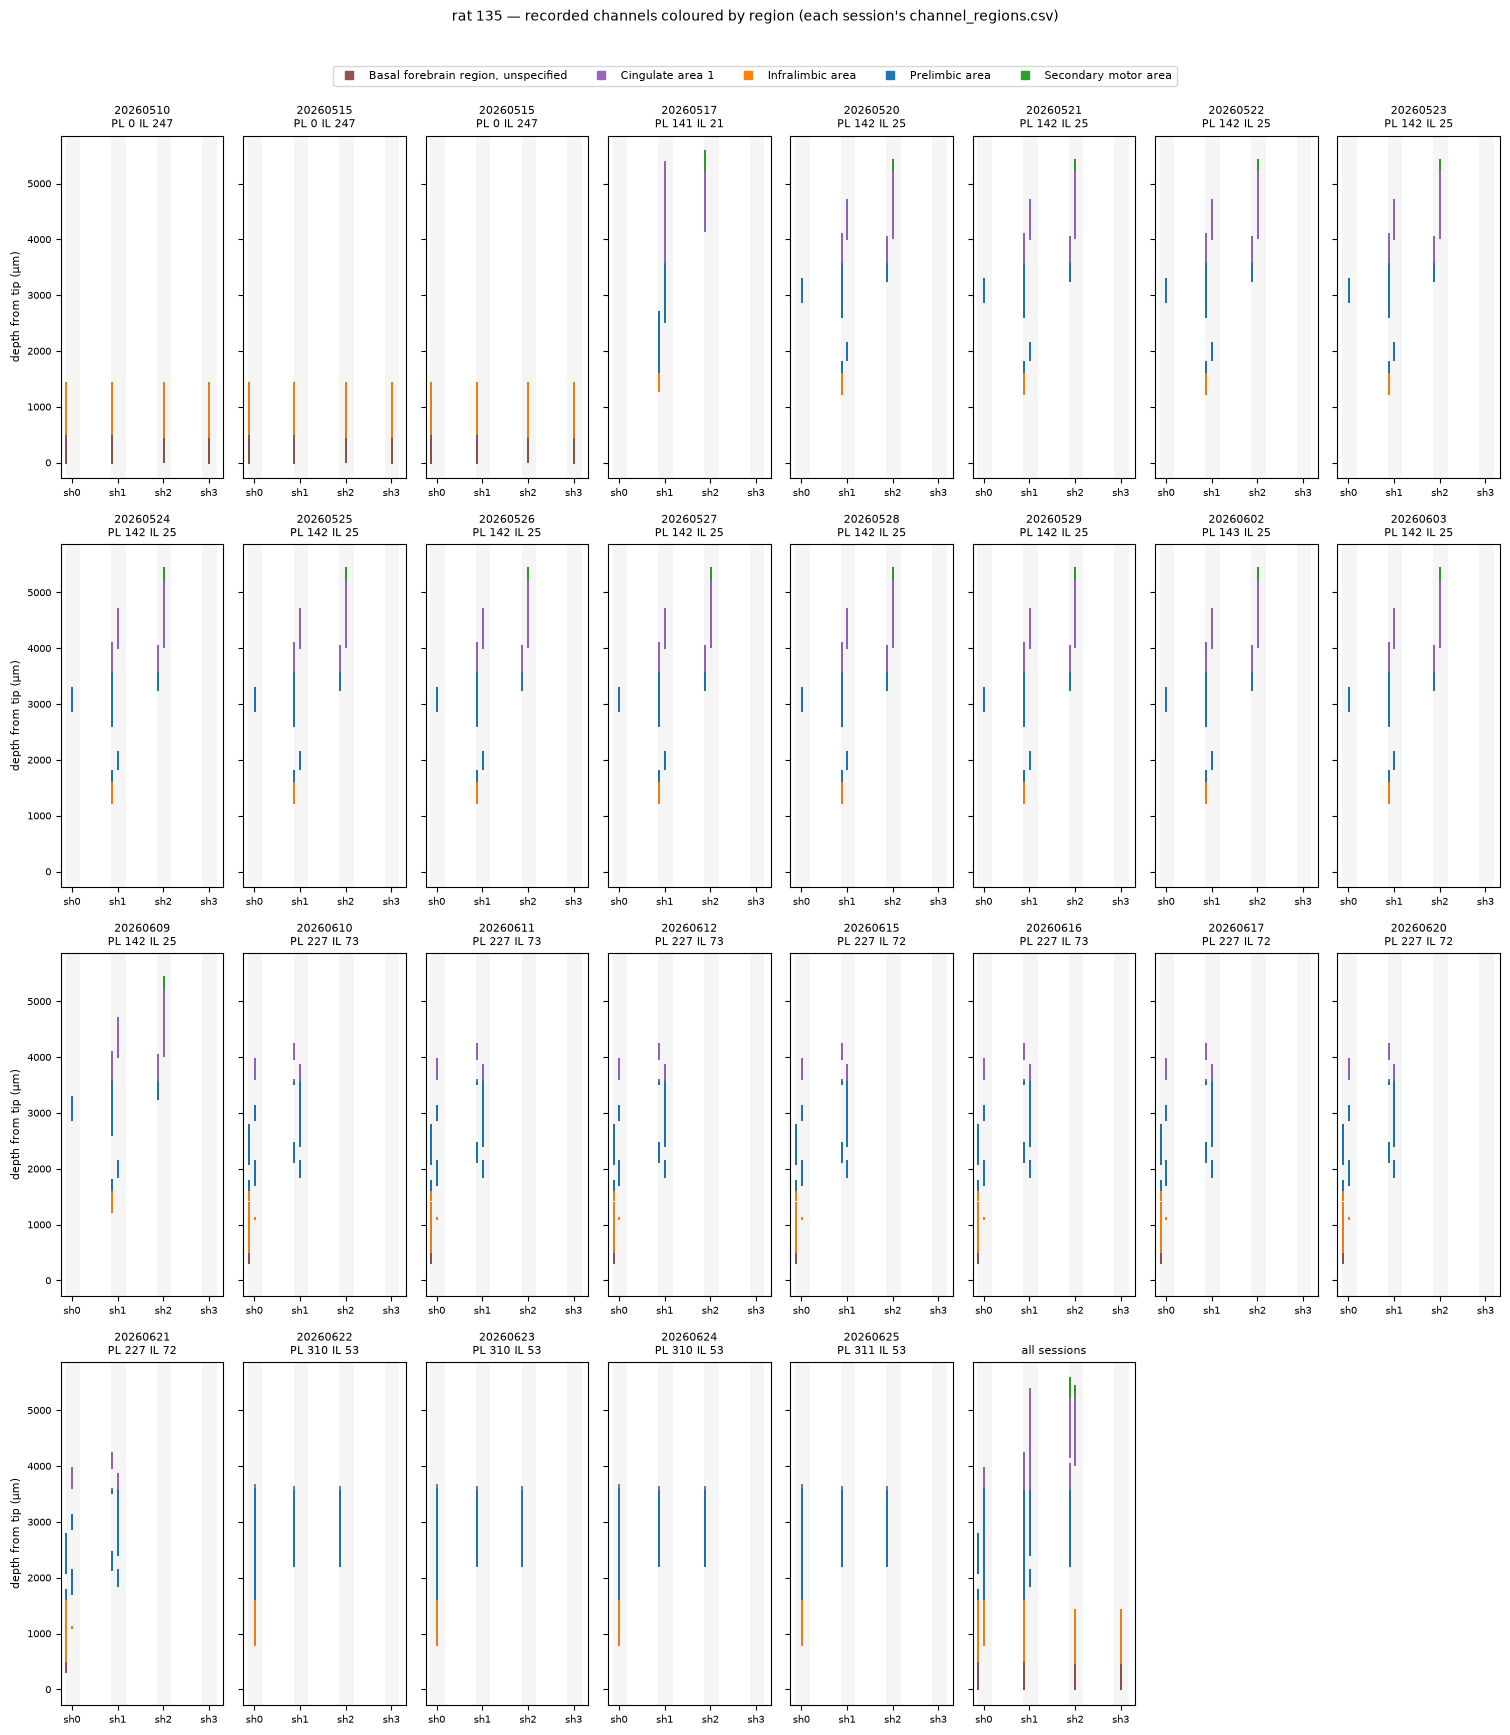

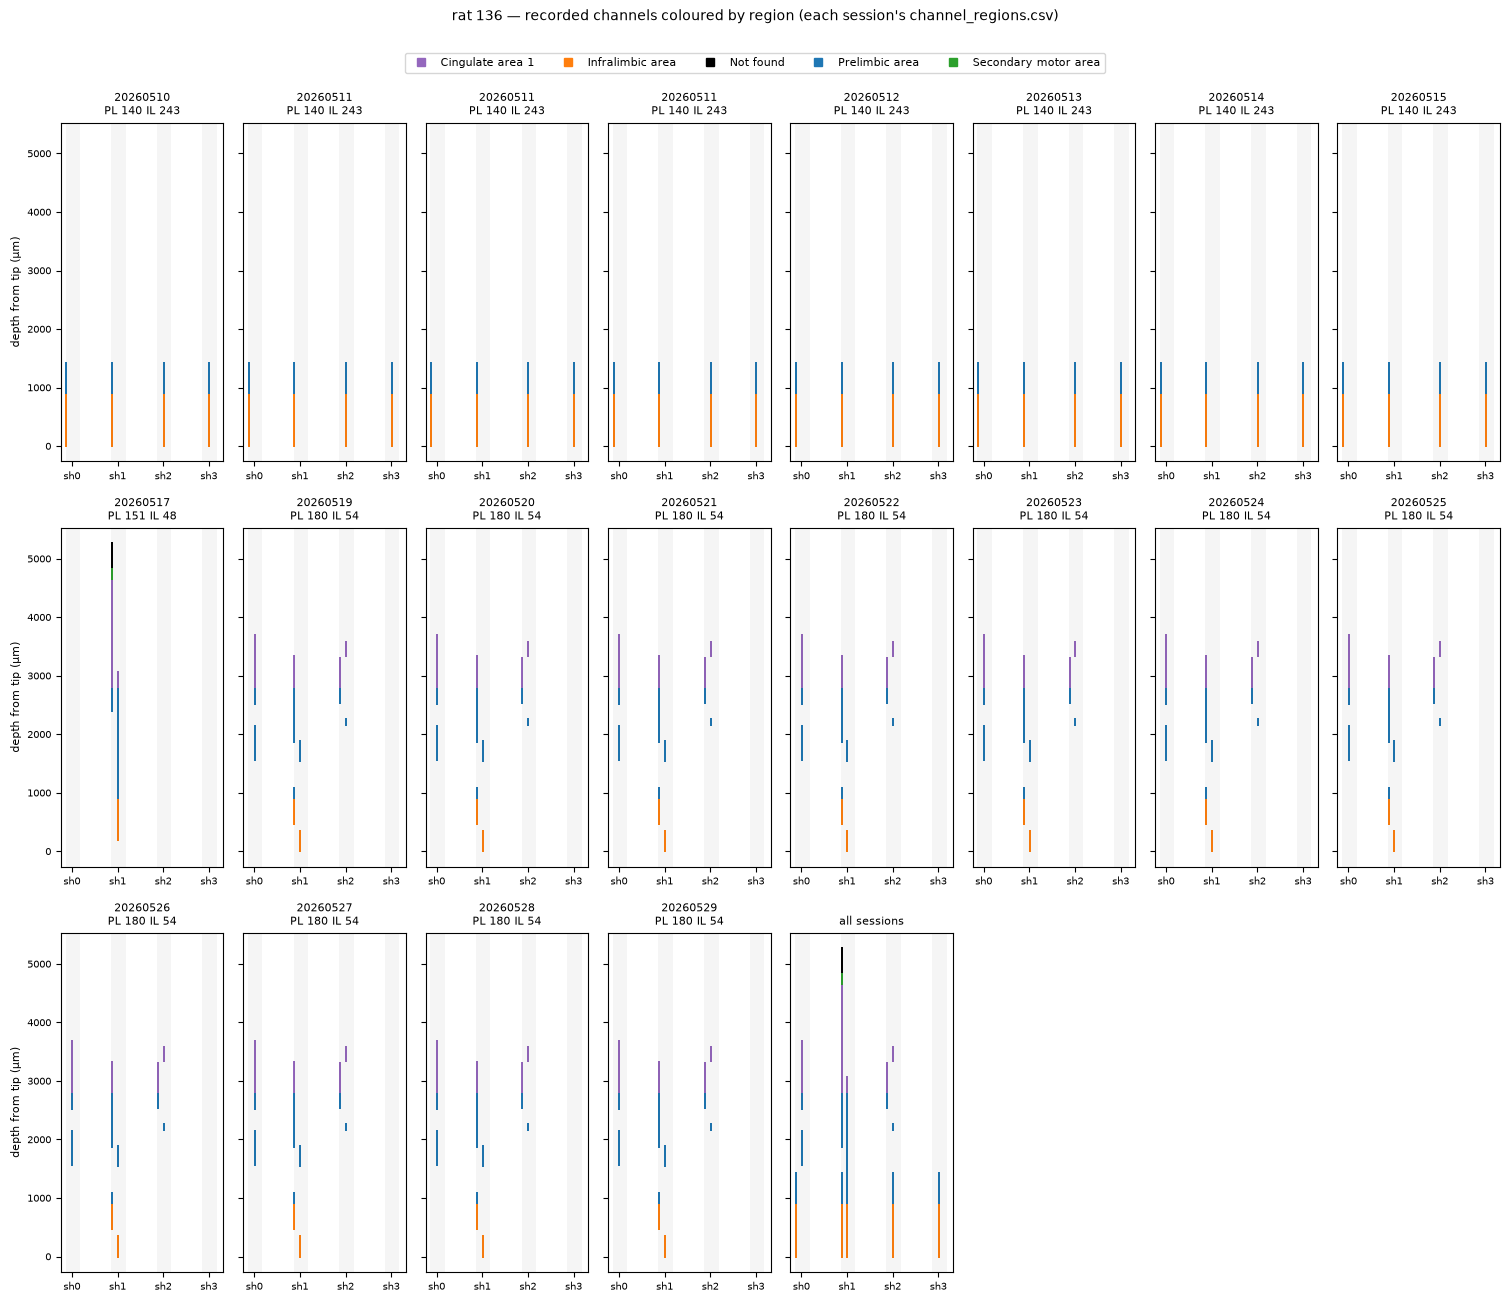

In [22]:
# %%
# ── P3 figures: per rat, one panel per session + all sessions together ──
REG_COL = {"Infralimbic area": "tab:orange", "Prelimbic area": "tab:blue", "Cingulate area 1": "tab:purple",
           "Secondary motor area": "tab:green", "Basal forebrain region, unspecified": "tab:brown",
           "Not found": "black", "NOT IN FILE": "lightgrey"}
def _col(r):
    return REG_COL.get(r, "tab:green")                                    # any other region = green

def _probe_panel(ax, m, title):
    for r, mm in m.groupby("region"):
        ax.scatter(mm["x"], mm["y"], s=4, color=_col(r), marker="s", linewidths=0)
    for sh in range(4):
        ax.axvspan(sh * 250 - 5, sh * 250 + 75, color="k", alpha=0.04, lw=0)
    ax.set_xlim(-30, 860); ax.set_xticks([30, 280, 530, 780]); ax.set_xticklabels(["sh0", "sh1", "sh2", "sh3"], fontsize=7)
    ax.set_title(title, fontsize=8); ax.tick_params(labelsize=7)

for rat, mr in CH_REG.groupby("rat"):
    sess = sorted(mr["session"].unique())
    ncol = min(8, len(sess) + 1); nrow = int(np.ceil((len(sess) + 1) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(1.9 * ncol, 4.2 * nrow), sharey=True, squeeze=False)
    axes = axes.ravel()
    for ax, s in zip(axes, sess):
        m = mr[mr["session"] == s]
        _probe_panel(ax, m, f"{s.split('_')[0]}\nPL {(m.region == 'Prelimbic area').sum()} IL {(m.region == 'Infralimbic area').sum()}")
    _probe_panel(axes[len(sess)], mr.drop_duplicates(["x", "y", "region"]), "all sessions")
    for ax in axes[len(sess) + 1:]:
        ax.axis("off")
    for ax in axes[::ncol]:
        ax.set_ylabel("depth from tip (µm)", fontsize=8)
    h = [plt.Line2D([], [], marker="s", ls="", color=_col(r), label=r) for r in sorted(mr["region"].unique())]
    fig.legend(handles=h, loc="upper center", ncol=len(h), fontsize=8, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(f"rat {rat} — recorded channels coloured by region (each session's channel_regions.csv)", fontsize=10, y=1.03)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_LOC, f"probe_regions_rat_{rat}.png"), dpi=150, bbox_inches="tight")
    plt.show()

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### P4: probe orientation in the brain
From the brain coordinates of each channel (channel_regions_all.csv): per session and shank median ML/AP, DV range, and tilt
(angle of ML change along DV). Then the ML and AP spread between the shanks within a session.
mPFC layers run parallel to the midline -> spread in ML = across layers, spread in AP = along the same layers.

<div>


In [23]:
# %%
# ── P4 probe orientation: do the 4 shanks span ML (across mPFC layers) or AP? is each shank tilted? ──
C = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv"))
C["rat"] = C["session"].str.extract(r"r0000(\d{3})")[0]
C["shank"] = (C["x"] // 250).astype(int)
rows = []
for (rat, s), d in C.groupby(["rat", "session"]):
    for sh, g in d.groupby("shank"):
        g = g.dropna(subset=["ml_mm", "dv_mm", "ap_mm"])
        if len(g) < 10: continue
        dml = np.polyfit(g["dv_mm"], g["ml_mm"], 1)[0]               # change in ML per mm DV along the shank
        rows.append(dict(rat=rat, session=s, shank=sh, n_ch=len(g), ml_mm=g["ml_mm"].median(), ap_mm=g["ap_mm"].median(),
                         dv_top=g["dv_mm"].max(), dv_bottom=g["dv_mm"].min(),
                         tilt_deg=np.degrees(np.arctan(abs(dml)))))
OR = pd.DataFrame(rows)
print("per rat (median over sessions) — one row per shank:")
print(OR.groupby(["rat", "shank"])[["ml_mm", "ap_mm", "dv_top", "dv_bottom", "tilt_deg"]].median().round(2).to_string())
print("\nspread between shanks within a session (median over sessions):")
sp = OR.groupby(["rat", "session"]).agg(ml_span=("ml_mm", lambda v: v.max() - v.min()),
                                        ap_span=("ap_mm", lambda v: v.max() - v.min())).groupby("rat").median().round(2)
print(sp.to_string())

per rat (median over sessions) — one row per shank:
           ml_mm  ap_mm  dv_top  dv_bottom  tilt_deg
rat shank                                           
134 1       0.72   2.54   -3.20      -5.86       0.0
    2       0.47   2.53   -3.20      -5.88       0.0
    3       0.22   2.39   -3.00      -5.49       0.0
135 0      -0.03   2.40   -3.51      -5.96       0.0
    1      -0.28   2.27   -2.58      -5.53       0.0
    2      -0.52   2.04   -1.40      -3.54       0.0
    3      -0.78   2.67   -5.34      -6.75       0.0
136 0      -0.12   2.08   -2.38      -4.48       0.0
    1      -0.38   2.23   -2.74      -6.02       0.0
    2      -0.62   2.05   -2.49      -3.89       0.0
    3      -0.88   2.44   -4.61      -6.02       0.0

spread between shanks within a session (median over sessions):
     ml_span  ap_span
rat                  
134     0.25     0.00
135     0.50     0.20
136     0.50     0.18


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### P4b: probe position in brain coordinates
Per rat: coronal (ML × DV) coloured by region and by shank, sagittal (AP × DV) coloured by shank; dashed line = midline.
All electrode positions recorded in the rat's final sessions (one dot per position).
Saved: figures/probe_location/probe_orientation_brain.png.

<div>

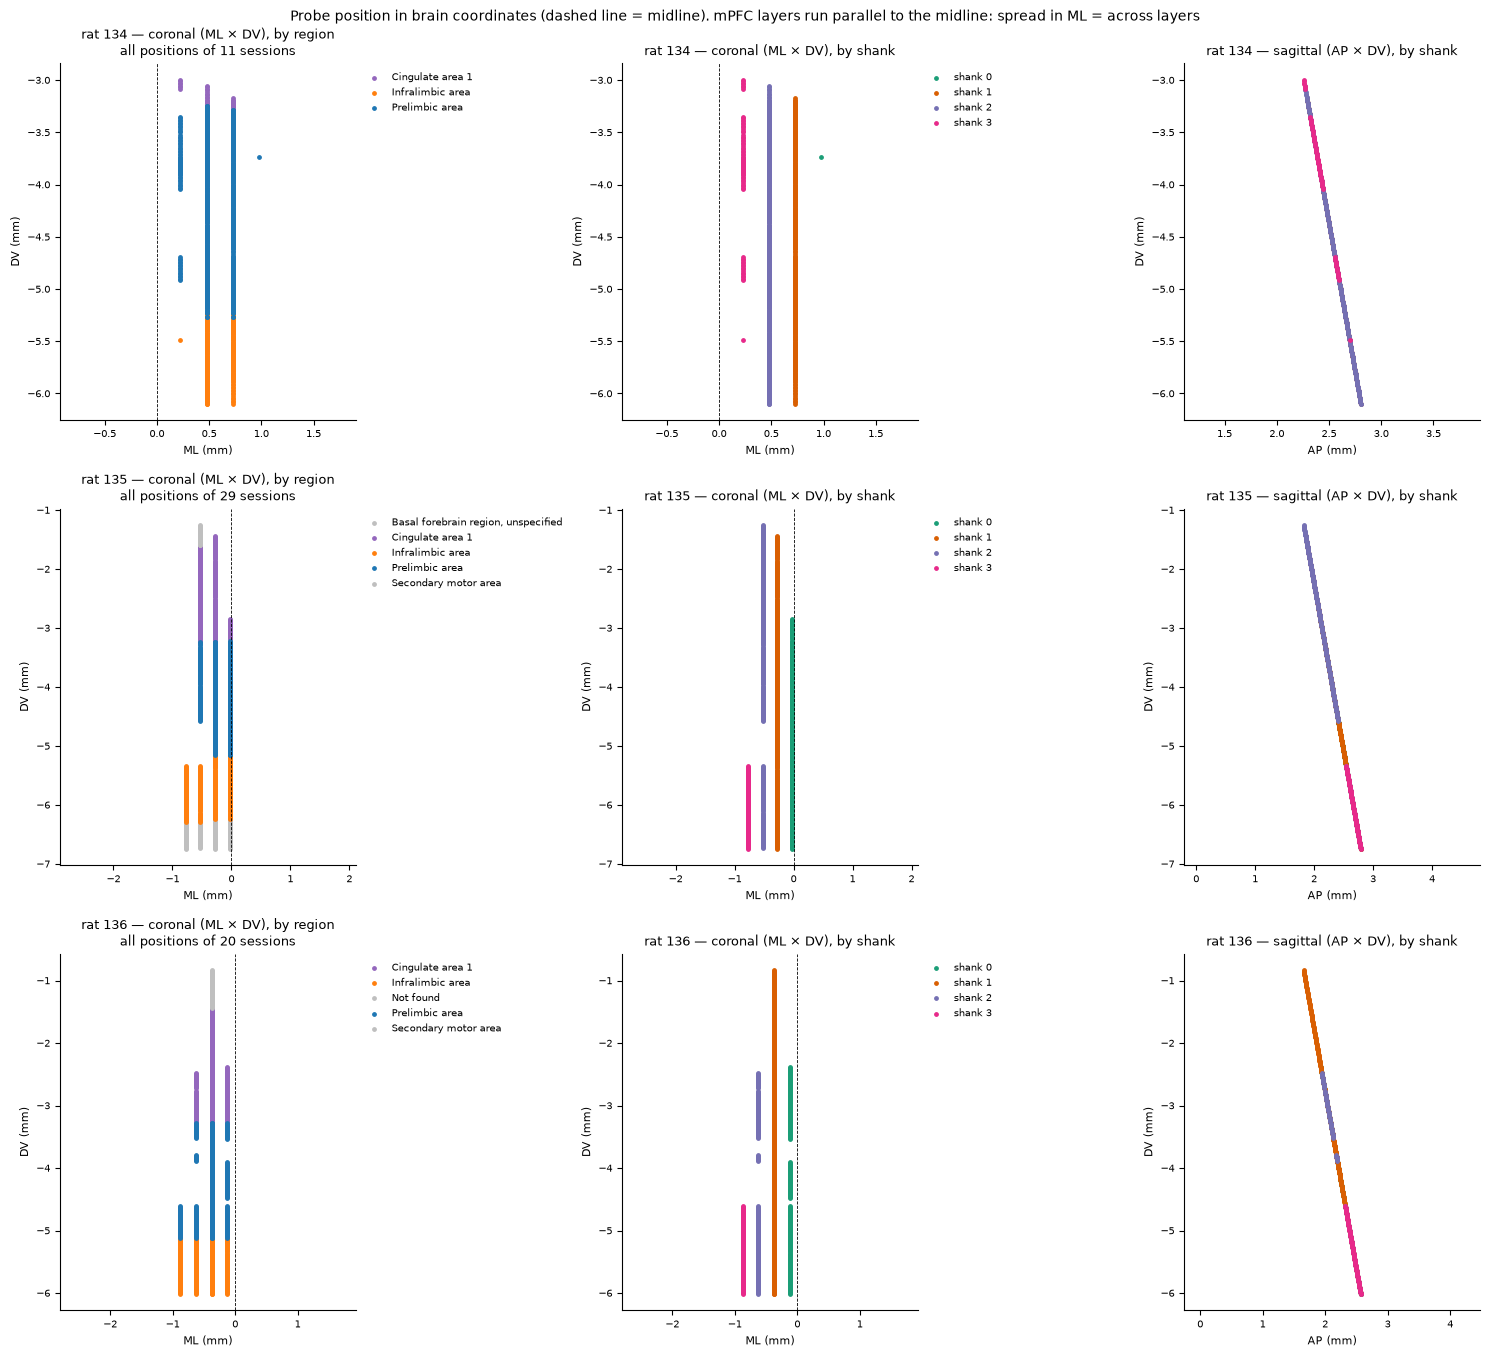

In [24]:
# %%
# ── P4b plot probe position in the brain: coronal (ML × DV) and sagittal (AP × DV), all positions per rat ──
REG_COL4 = {"Prelimbic area": "#1f77b4", "Infralimbic area": "#ff7f0e", "Cingulate area 1": "#9467bd"}
SH_COL = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a"]
rats = sorted(C["rat"].unique())
fig, axes = plt.subplots(len(rats), 3, figsize=(15, 4.6 * len(rats)), squeeze=False)
for i, rat in enumerate(rats):
    d = (C[C.rat == rat].dropna(subset=["ml_mm", "dv_mm", "ap_mm"])
         .drop_duplicates(["x", "y"]))                                   # every electrode position once
    n_s = C.loc[C.rat == rat, "session"].nunique()
    ax = axes[i, 0]                                                       # coronal, coloured by region
    for reg, g in d.groupby("region"):
        ax.scatter(g["ml_mm"], g["dv_mm"], s=6, color=REG_COL4.get(reg, "0.75"), label=reg)
    ax.set_title(f"rat {rat} — coronal (ML × DV), by region\nall positions of {n_s} sessions", fontsize=9)
    ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    ax = axes[i, 1]                                                       # coronal, coloured by shank
    for sh, g in d.groupby("shank"):
        ax.scatter(g["ml_mm"], g["dv_mm"], s=6, color=SH_COL[sh % 4], label=f"shank {sh}")
    ax.set_title(f"rat {rat} — coronal (ML × DV), by shank", fontsize=9)
    ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    ax = axes[i, 2]                                                       # sagittal, coloured by shank
    for sh, g in d.groupby("shank"):
        ax.scatter(g["ap_mm"], g["dv_mm"], s=6, color=SH_COL[sh % 4], label=f"shank {sh}")
    ax.set_title(f"rat {rat} — sagittal (AP × DV), by shank", fontsize=9)
    for j, xl in enumerate(["ML (mm)", "ML (mm)", "AP (mm)"]):
        a = axes[i, j]; a.set_xlabel(xl, fontsize=8); a.set_ylabel("DV (mm)", fontsize=8); a.tick_params(labelsize=7)
        for sp_ in ("top", "right"): a.spines[sp_].set_visible(False)
    for j in (0, 1):                                                      # same scale on both axes, midline at ML = 0
        axes[i, j].axvline(0, color="k", lw=0.6, ls="--"); axes[i, j].set_aspect("equal", adjustable="datalim")
    axes[i, 2].set_aspect("equal", adjustable="datalim")
fig.suptitle("Probe position in brain coordinates (dashed line = midline). mPFC layers run parallel to the midline: "
             "spread in ML = across layers", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(FIG_LOC, "probe_orientation_brain.png"), dpi=140, bbox_inches="tight")
plt.show()

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### Session summary figure
The session summary table drawn as a figure: rows grouped by rat with totals, counts shaded by size,
red = sync problems, italic = single-WT session. Saved: tables/session_summary.png and .pdf.

<div>

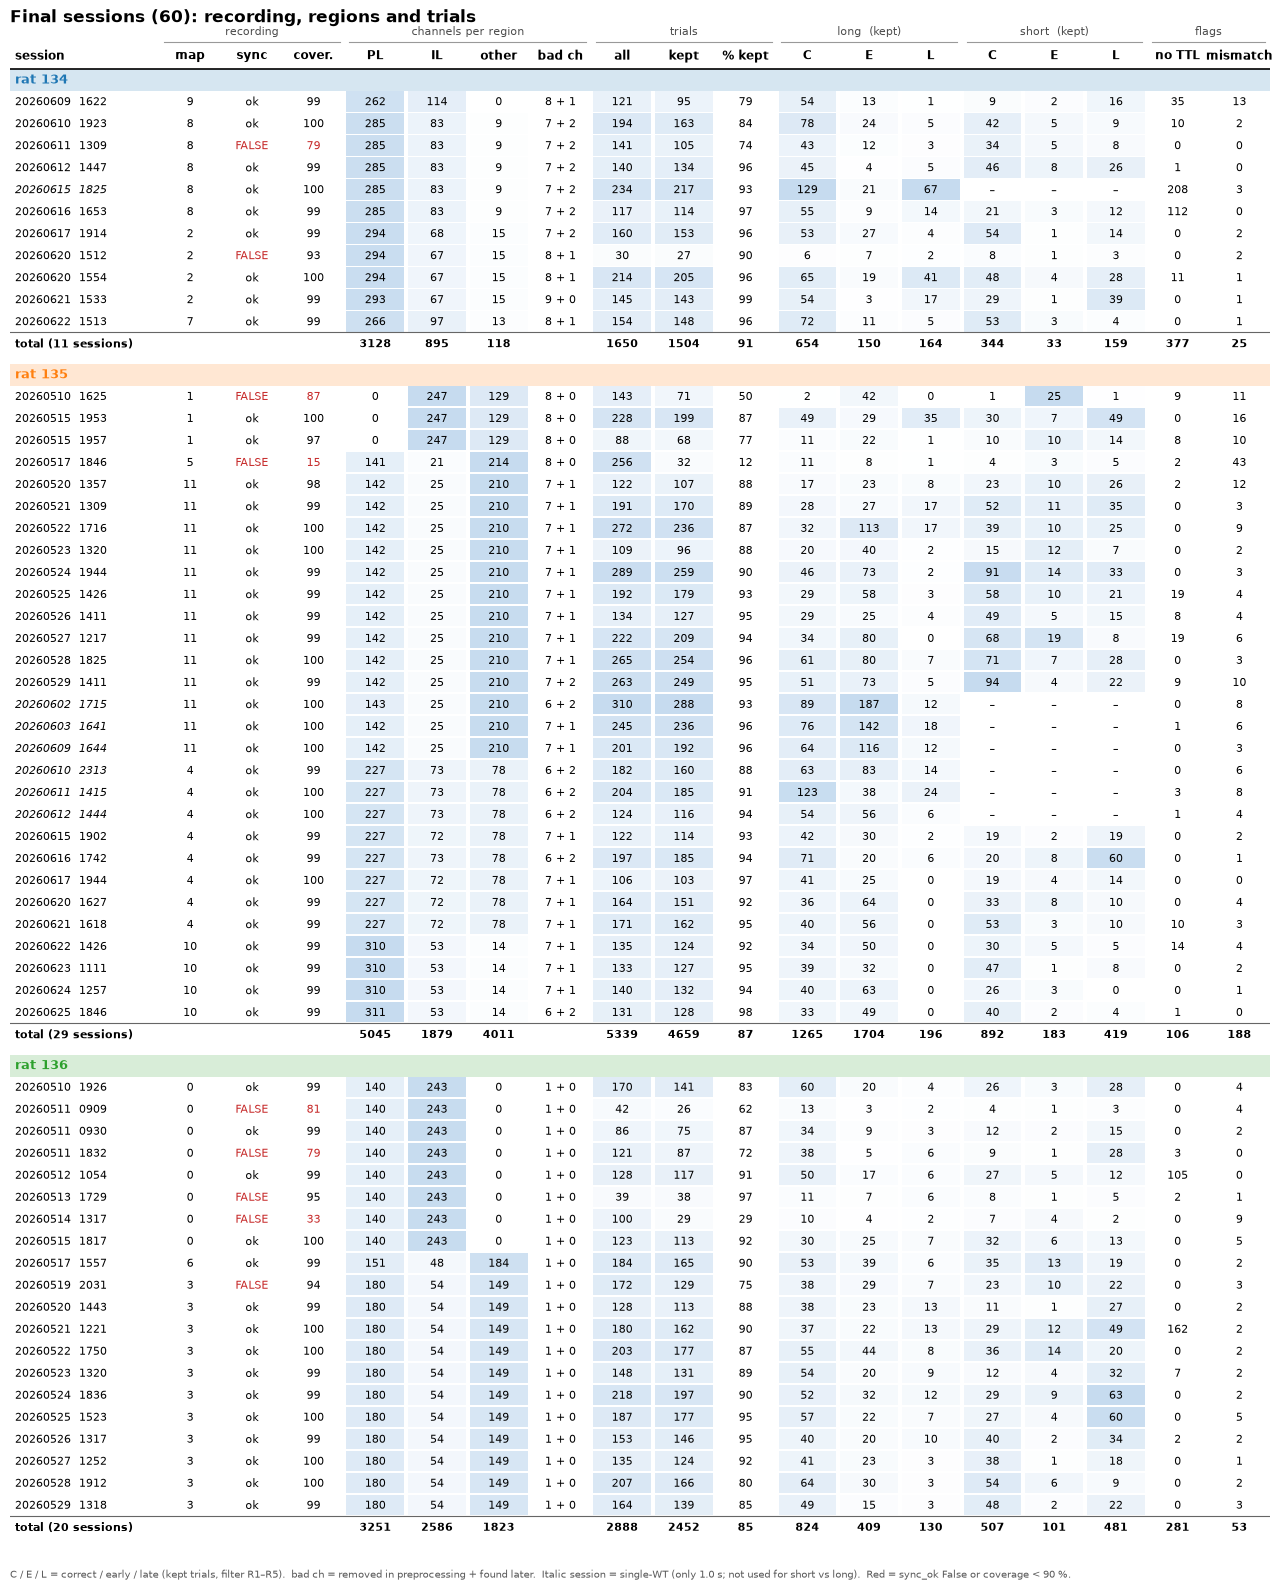

In [26]:
# %%
# ── SESSION SUMMARY as a figure (one row per session, grouped by rat) ──
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

COLS = [  # (column in S, header, kind)   kind: text / num (shaded) / plain
    ("session", "session", "text"), ("map_id", "map", "plain"),
    ("sync_ok", "sync", "sync"), ("sync_coverage", "cover.", "pct"),
    ("n_PL", "PL", "num"), ("n_IL", "IL", "num"), ("n_other", "other", "num"),
    ("bad", "bad ch", "plain"),
    ("n_trials_all", "all", "num"), ("n_trials_kept", "kept", "num"), ("pct_kept", "% kept", "pct"),
    ("long_correct", "C", "num"), ("long_early", "E", "num"), ("long_late", "L", "num"),
    ("short_correct", "C", "num"), ("short_early", "E", "num"), ("short_late", "L", "num"),
    ("n_press_np_s", "no TTL", "plain"), ("n_timing_mismatch", "mismatch", "plain")]
GROUPS = [("recording", 1, 4), ("channels per region", 4, 8), ("trials", 8, 11),
          ("long  (kept)", 11, 14), ("short  (kept)", 14, 17), ("flags", 17, 19)]
WIDTH = {"session": 1.5, "sync": 0.6}                     # column widths (inch); others 0.62
RAT_COL = {"134": "#1f77b4", "135": "#ff7f0e", "136": "#2ca02c"}
CMAP = LinearSegmentedColormap.from_list("shade", ["#ffffff", "#c6dbef"])

T = S.copy()
T["bad"] = T["n_bad_preproc"].astype(int).astype(str) + " + " + T["n_bad_extra"].astype(int).astype(str)
T["pct_kept"] = T["n_trials_kept"] / T["n_trials_all"]
T["session"] = T["session"].str.replace(r"_r0000\d{3}_wt_", "  ", regex=True)       # 20260510  1625
for c in ["short_correct", "short_early", "short_late"]:
    T[c] = T[c].astype(object).where(~T["single_wt_session"].astype(bool), "–")      # no short trials

# rows: rat header, sessions, rat total
lines = []
for rat, g in T.groupby("rat"):
    lines.append(("rat", rat, None))
    for _, r in g.iterrows():
        lines.append(("sess", rat, r))
    gs = S[S["rat"] == rat]                                            # numeric version (short columns of T contain "–")
    tot = {c: gs[c].sum() for c, _, k in COLS if k == "num"}
    tot.update(session=f"total ({len(g)} sessions)", pct_kept=g["n_trials_kept"].sum() / g["n_trials_all"].sum(),
               n_press_np_s=g["n_press_np_s"].sum(), n_timing_mismatch=g["n_timing_mismatch"].sum())
    lines.append(("tot", rat, tot))

xs = np.cumsum([0] + [WIDTH.get(c, 0.62) for c, _, _ in COLS])
RH = 0.22                                                              # row height (inch)
H = (len(lines) + 4.5) * RH
fig = plt.figure(figsize=(xs[-1] + 0.2, H + 0.6))
ax = fig.add_axes([0.01, 0.01, 0.98, H / (H + 0.6)])
ax.set_xlim(0, xs[-1]); ax.set_ylim(H, 0); ax.axis("off")
vmax = {c: S[c].max() for c, _, k in COLS if k == "num"}

# header: groups + column names
for name, a, b in GROUPS:
    ax.text((xs[a] + xs[b]) / 2, 0.5 * RH, name, ha="center", va="center", fontsize=8, color="0.3")
    ax.plot([xs[a] + 0.05, xs[b] - 0.05], [0.95 * RH] * 2, color="0.6", lw=0.8)
for j, (c, h, _) in enumerate(COLS):
    ax.text(xs[j] + (0.05 if j == 0 else (xs[j + 1] - xs[j]) / 2), 1.6 * RH, h, fontsize=8.5, fontweight="bold",
            ha="left" if j == 0 else "center", va="center")
ax.plot([0, xs[-1]], [2.2 * RH] * 2, color="k", lw=1.2)

y = 2.6 * RH
for kind, rat, r in lines:
    if kind == "rat":
        ax.add_patch(Rectangle((0, y - 0.4 * RH), xs[-1], RH, color=RAT_COL[rat], alpha=0.18, lw=0))
        ax.text(0.05, y + 0.1 * RH, f"rat {rat}", fontsize=9, fontweight="bold", color=RAT_COL[rat], va="center")
        y += RH; continue
    for j, (c, _, k) in enumerate(COLS):
        v = r.get(c, "") if kind == "tot" else r[c]
        x0, x1 = xs[j], xs[j + 1]
        if kind == "sess" and k == "num" and isinstance(v, (int, float, np.integer, np.floating)) and vmax.get(c):
            ax.add_patch(Rectangle((x0 + 0.02, y - 0.4 * RH), x1 - x0 - 0.04, RH * 0.92,
                                   color=CMAP(float(v) / vmax[c]), lw=0))
        col, txt = "k", v
        if k == "sync":
            txt = "" if kind == "tot" else ("ok" if v else "FALSE"); col = "k" if v else "#c62828"
        elif k == "pct":
            txt = "" if v == "" or pd.isna(v) else f"{100 * v:.0f}"
            if c == "sync_coverage" and kind == "sess" and v < 0.9: col = "#c62828"
        elif isinstance(v, (float, np.floating)) and float(v).is_integer():
            txt = int(v)
        ax.text(x0 + (0.05 if j == 0 else (x1 - x0) / 2), y + 0.1 * RH, txt, fontsize=8, color=col,
                ha="left" if j == 0 else "center", va="center",
                fontweight="bold" if kind == "tot" else "normal",
                style="italic" if kind == "sess" and j == 0 and r["single_wt_session"] else "normal")
    if kind == "tot":
        ax.plot([0, xs[-1]], [y - 0.45 * RH] * 2, color="0.4", lw=0.8)
        y += 0.4 * RH
    y += RH

ax.text(0, y + 0.6 * RH, "C / E / L = correct / early / late (kept trials, filter R1–R5).  bad ch = removed in preprocessing + found later.  "
        "Italic session = single-WT (only 1.0 s; not used for short vs long).  Red = sync_ok False or coverage < 90 %.",
        fontsize=7, color="0.35", va="top")
fig.suptitle(f"Final sessions ({len(T)}): recording, regions and trials", fontsize=12, fontweight="bold", x=0.01, ha="left")
fig.savefig(os.path.join(TABLES, "session_summary.png"), dpi=200, bbox_inches="tight")
fig.savefig(os.path.join(TABLES, "session_summary.pdf"), bbox_inches="tight")
plt.show()

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## Save figures to the project folder
Copies the figures of this notebook to O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data,
each renamed for what it shows:
- depth coverage (final sessions per shank × 100 µm bin, per rat)
- session summary table (final sessions: recording, regions, trials)
- P3 recorded channels coloured by brain region, one figure per rat
- P4b probe position in brain coordinates (all rats)

<div>